In [ ]:
from pathlib import Path
import sys
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'data' / 'news_article_dataset.json').exists())
DATA_DIR = PROJECT_ROOT / 'data'
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT))


# News position classification

I test whether article text predicts the left, center, or right label assigned in the source dataset. The label is taken from the roundup data; the model does not independently establish an article’s political bias.


## Approach

I reshape the roundup file into article rows, compare two cleaning methods, and split the rows by publication date. TF-IDF and truncated SVD provide features for a feed-forward network. I use the newest articles only for the final test.


## Imports

The notebook uses pandas for data handling, scikit-learn for text features and evaluation, and PyTorch for training. NLTK supplies stop words and lemmatization for the extended cleaning run.


In [1]:
# %% [markdown]
# ## Imports and Setup
# Import standard libraries first, followed by external packages.

import random
import re
import string

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from urllib.parse import urlparse

from collections import Counter

from gensim.models import KeyedVectors
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import classification_report, roc_curve, auc
from sklearn.model_selection import StratifiedKFold

# Download necessary NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')


[nltk_data] Downloading package punkt to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

## Random seed

I set seeds for Python, NumPy, and PyTorch before training. This reduces variation between runs, although results can still vary across hardware and library versions.


In [2]:
def set_seed(seed=42):
    """Set seed for reproducibility across various libraries."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

## Load the articles

The source file stores up to three article versions under each roundup. I extract the available title, text, topic, date, and URL for each position, then derive a source name from the URL.


In [3]:
def extract_source(url):
    """Extract the source name from a URL by parsing its domain."""
    try:
        parsed = urlparse(url)
        domain = parsed.netloc
        if domain.startswith('www.'):
            domain = domain[4:]
        # Take the first part of the domain (e.g., 'cnn' from 'cnn.com')
        source = domain.split('.')[0]
        return source
    except Exception as e:
        return None


def get_data_df(file_path):
    """
    Load data from a JSON-lines file and extract article information for each political position.
    
    Parameters:
      - file_path: path to the JSON-lines file
    
    Returns:
      - DataFrame with columns: title, topic, text, position, source, date
    """
    df_data = pd.read_json(file_path, orient='records', lines=True)
    output_rows = []
    
    # Define keys to extract data
    title_key, text_key, url_key, topic_key, date_key = "story_title", "story_text", "story_url", "Topics", "Date"
   
    for _, row in df_data.iterrows():
        for position in ['center', 'left', 'right']:
            if pd.isna(row.get(f"{position}_{title_key}")):
                continue
            title = row[f"{position}_{title_key}"]
            text = row[f"{position}_{text_key}"]
            link = row[f"{position}_{url_key}"]
            topic = row[topic_key].lower()
            date = row[date_key]
            source = extract_source(link)
            output_rows.append({
                "title": title,
                "topic": topic,
                "text": text,
                "position": position,
                "source": source,
                "date": date
            })

    result_df = pd.DataFrame(output_rows)
    return result_df

# Load the dataset and fill missing values
file_path = DATA_DIR / 'news_article_dataset.json'
result_df = get_data_df(file_path)
result_df = result_df.fillna('')
display(result_df.head())
print('Data shape is:', result_df.shape)

,title,topic,text,position,source,date
0,Shaky Start for Romney Overseas Trip,elections,Mitt Romney launched an overseas tour Thursday...,center,online,2012-07-26
1,Romney's Olympics false start,elections,Mitt Romney told British leaders he hopes to t...,left,politicalticker,2012-07-26
2,Romney causes London stir over Olympic readine...,elections,"The Brits, taking a break from beating up on t...",right,politics,2012-07-26
3,Romney's Overseas Trip Produces Hits and Misses,elections,"WARSAWâ€”With a speech lauding Poland as a ""de...",center,online,2012-08-01
4,Was Romney's trip 'a great success' or gaffe-f...,elections,OPINION\nWarsaw (CNN) -- In the estimation of ...,left,cnn,2012-08-01


Data shape is: (24523, 6)


The reshape step gives 24,523 article rows in this run: 7,706 center, 8,436 left, and 8,381 right. Each row has a title, topic, body text, position, source, and date. Missing values are filled before the text fields are combined.


## Article counts

I plot sources with more than 100 articles and the number of articles by publication year. These counts show where this sample is concentrated.


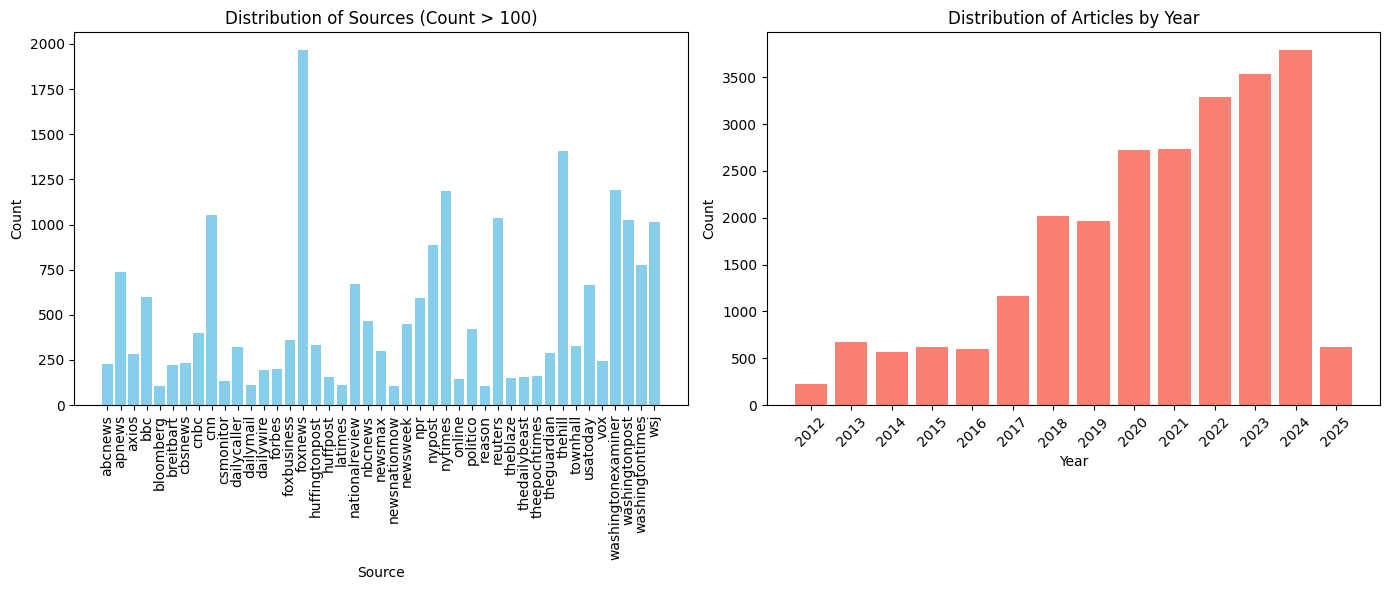

In [4]:
# Convert 'date' column to datetime
result_df['date'] = pd.to_datetime(result_df['date'])

# Distribution of sources (only sources with > 100 articles)
source_counts = result_df['source'].value_counts()
source_counts_filtered = source_counts[source_counts > 100].sort_index()

# Distribution of articles by publication year
date_counts = result_df['date'].dt.to_period('Y').value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].bar(source_counts_filtered.index, source_counts_filtered.values, color='skyblue')
axes[0].set_title('Distribution of Sources (Count > 100)')
axes[0].set_xlabel('Source')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=90)

axes[1].bar([str(year) for year in date_counts.index], date_counts.values, color='salmon')
axes[1].set_title('Distribution of Articles by Year')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

The source chart highlights publishers that contribute many articles; the year chart shows when this collection is densest. Neither chart measures the volume of news outside this dataset. Repeated sources across periods could also make the classification task easier.


## Topics and position labels

I compare topic frequencies with the counts of left, center, and right labels.


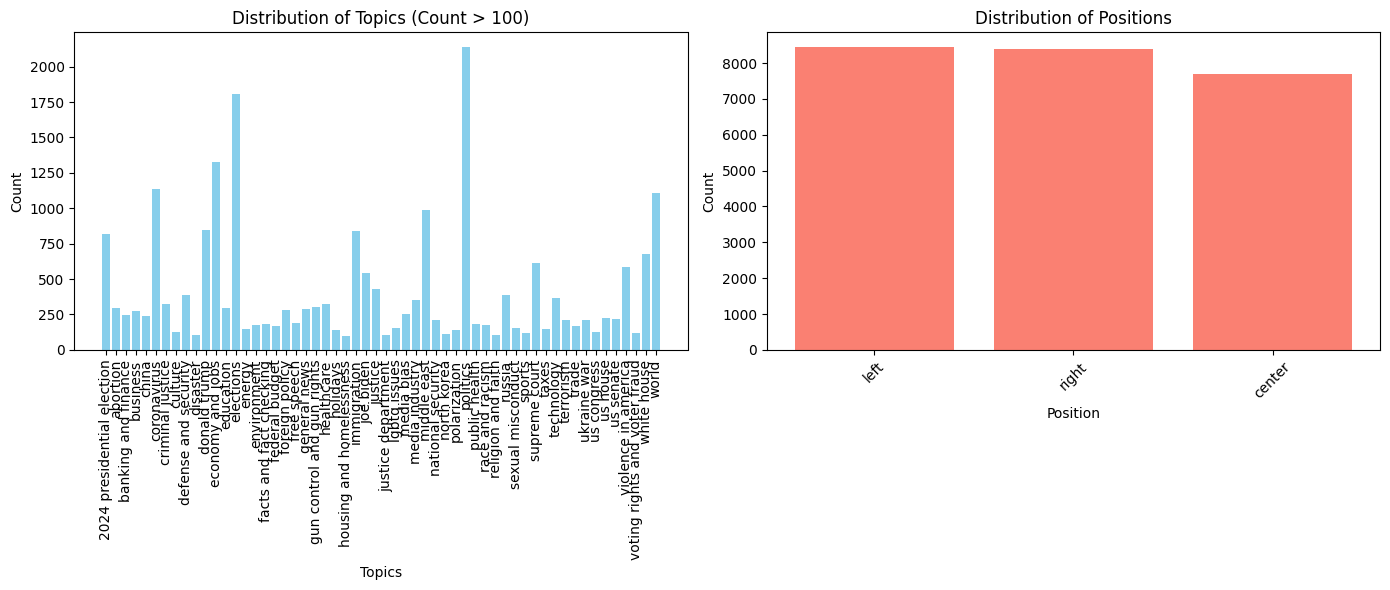

In [5]:
# Distribution of topics and positions
position_counts = result_df['position'].value_counts()
topic_counts = result_df['topic'].value_counts()
topic_counts_filtered = topic_counts[topic_counts > 100].sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].bar(topic_counts_filtered.index, topic_counts_filtered.values, color='skyblue')
axes[0].set_title('Distribution of Topics (Count > 100)')
axes[0].set_xlabel('Topics')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=90)

axes[1].bar(position_counts.index, position_counts.values, color='salmon')
axes[1].set_title('Distribution of Positions')
axes[1].set_xlabel('Position')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

The three position labels have similar counts, while topic coverage is less even. Politics and elections are the most common topics in the reshaped data. A balanced target helps interpret accuracy, yet it does not guarantee equal coverage of sources or subjects.


## Text cleaning

Basic cleaning lowercases text and collapses extra spaces. Extended cleaning removes punctuation and English stop words and lemmatizes the remaining words. I compare them because extra cleaning can remove useful wording as well as noise.


In [6]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def normalize_text(text):
    """Lowercase text and remove extra whitespace."""
    return ' '.join(text.lower().split())

def extended_normalize_text(text):
    """Remove punctuation, lowercase, remove stopwords and lemmatize tokens."""
    text = text.translate(str.maketrans('', '', string.punctuation))
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return ' '.join(tokens)

## Model input

I join each article’s title, body text, and topic into one field, then apply basic normalization. Including the topic gives the model more context, but it also means the score cannot be attributed to article wording alone.


In [7]:
# Combine title, text, and topic columns and apply basic normalization
filtered_df = result_df.copy()
filtered_df['combined'] = (filtered_df['title'] + ' ' + filtered_df['text'] + ' ' + filtered_df['topic']).apply(normalize_text)

## Split by date

The `Preprocessing` helper sorts articles by publication date. The oldest 80% form the training and validation period; the newest 20% are held out for a later test.


In [8]:
import importlib
import utils
importlib.reload(utils)

Preprocessing = utils.Preprocessing

# Set maximum vocabulary size and split ratio
max_vocab = 20000
preprocessor = Preprocessing(max_len=200, test_ratio=0.2)
train_val_df, test_df = preprocessor.split_data(result_df=filtered_df)

print('Training DataFrame:', train_val_df.shape)
display(train_val_df.head())

print('Testing DataFrame:', test_df.shape)
display(test_df.head())

Training DataFrame: (19618, 7)


[nltk_data] Downloading package stopwords to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


,title,topic,text,position,source,date,combined
0,Shaky Start for Romney Overseas Trip,elections,Mitt Romney launched an overseas tour Thursday...,center,online,2012-07-26,shaky start for romney overseas trip mitt romn...
1,Romney's Olympics false start,elections,Mitt Romney told British leaders he hopes to t...,left,politicalticker,2012-07-26,romney's olympics false start mitt romney told...
2,Romney causes London stir over Olympic readine...,elections,"The Brits, taking a break from beating up on t...",right,politics,2012-07-26,romney causes london stir over olympic readine...
3,Romney's Overseas Trip Produces Hits and Misses,elections,"WARSAWâ€”With a speech lauding Poland as a ""de...",center,online,2012-08-01,romney's overseas trip produces hits and misse...
4,Was Romney's trip 'a great success' or gaffe-f...,elections,OPINION\nWarsaw (CNN) -- In the estimation of ...,left,cnn,2012-08-01,was romney's trip 'a great success' or gaffe-f...


Testing DataFrame: (4905, 7)


,title,topic,text,position,source,date,combined
0,IRS announces 2024 income tax brackets; see wh...,banking and finance,Millions of Americans could take home more pay...,center,newsnationnow,2023-11-10,irs announces 2024 income tax brackets; see wh...
1,News outlets deny Israeli claim that freelance...,facts and fact checking,A number of news outlets have strongly rejecte...,center,bbc,2023-11-10,news outlets deny israeli claim that freelance...
2,Senior Ukrainian Military Officer Behind Nord ...,ukraine war,A Ukrainian military officer involved with the...,right,dailycaller,2023-11-12,senior ukrainian military officer behind nord ...
3,Nord Stream Pipeline Explosion Was Orchestrate...,ukraine war,A decorated colonel in Ukraine’s special force...,center,themessenger,2023-11-12,nord stream pipeline explosion was orchestrate...
4,Ukrainian military officer coordinated Nord St...,ukraine war,A senior Ukrainian military officer with deep ...,left,washingtonpost,2023-11-12,ukrainian military officer coordinated nord st...


This run places 19,618 articles in the training and validation period and 4,905 in the test period. The date split asks whether the model can classify later articles after learning from earlier ones.


## Labels in each split

I compare class counts after the split instead of assuming the two periods have the same mix.


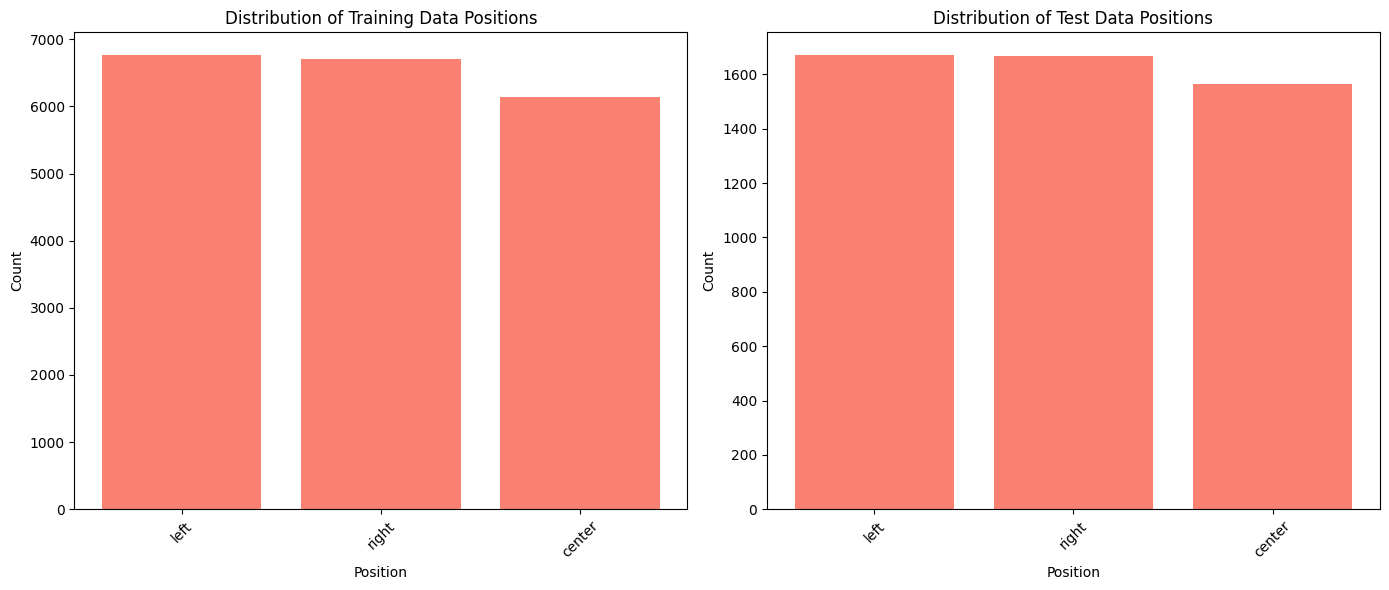

In [9]:
# Visualize distribution of positions in training and test sets
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

pos_counts_train = train_val_df['position'].value_counts()
axes[0].bar(pos_counts_train.index, pos_counts_train.values, color='salmon')
axes[0].set_title('Distribution of Training Data Positions')
axes[0].set_xlabel('Position')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

pos_counts_test = test_df['position'].value_counts()
axes[1].bar(pos_counts_test.index, pos_counts_test.values, color='salmon')
axes[1].set_title('Distribution of Test Data Positions')
axes[1].set_xlabel('Position')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

The plots show how many center, left, and right articles are in each period. The test set contains 1,566 center, 1,671 left, and 1,668 right articles; these counts also appear as support in the final classification reports.


## PyTorch dataset

The dataset class stores the LSI feature vectors as floating-point tensors and labels as integer tensors. Data loaders then pass them to the network in batches.


In [10]:
class TextDataset(Dataset):
    def __init__(self, X, y):
        # Use FloatTensor for standard features
        self.X = torch.FloatTensor(X) 
        self.y = torch.LongTensor(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

## Evaluation

Accuracy gives the overall share of correct predictions. Precision, recall, and F1 show performance for each label; the classification report also lists how many test articles belong to each class. ROC plots and sample predictions provide additional views.


In [11]:
def calculate_accuracy(y_true, preds):
    """Compute accuracy given true labels and prediction scores."""
    preds = torch.tensor(preds)
    preds = torch.argmax(preds, dim=-1)
    correct = (preds == y_true).float()
    return correct.sum() / len(correct)

def evaluation(model, data_loader):
    """Run model inference over the data loader and return concatenated predictions."""
    model.eval()
    predictions = []
    with torch.no_grad():
        for x_batch, _ in data_loader:
            y_pred = model(x_batch)
            predictions.append(y_pred.detach())
    return torch.cat(predictions, dim=0)

def evaluate_model(test_df, x_test, y_test, model, device, type):
    """
    Evaluate the model on the test set and display classification metrics and ROC curves.
    Also display sample predictions.
    """
    test_dataset = TextDataset(x_test, y_test)
    test_dataloader = DataLoader(test_dataset, batch_size=16, shuffle=False)
    
    model.eval()
    all_true, all_preds, all_probs = [], [], []
    with torch.no_grad():
        for batch_X, batch_y in test_dataloader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)
            all_true.extend(batch_y.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.append(probs.cpu().numpy())
    all_probs = np.vstack(all_probs)
    
    print('Classification Report:')
    print(classification_report(all_true, all_preds, target_names=preprocessor.le.classes_))
    
    # Plot ROC curves for each class
    num_classes = len(preprocessor.le.classes_)
    y_true_binarized = label_binarize(np.array(all_true), classes=range(num_classes))
    
    plt.figure(figsize=(6,6))
    for i in range(num_classes):
        fpr, tpr, _ = roc_curve(y_true_binarized[:, i], all_probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f"{preprocessor.le.classes_[i]} (AUC = {roc_auc:.2f})")
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve for Each Class ({type})')
    plt.legend(loc='lower right')
    plt.show()
    
    # Sample predictions for first 5 test examples
    sample_tensor = torch.FloatTensor(x_test[:5])
    sample_tensor = sample_tensor.to(device)
    with torch.no_grad():
        outputs = model(sample_tensor)
        sample_probs = torch.softmax(outputs, dim=1)
        sample_preds = torch.argmax(sample_probs, dim=1).cpu().numpy()
    sample_pred_labels = preprocessor.le.inverse_transform(sample_preds)

    sample_df = test_df.iloc[:5].copy()
    sample_df['predicted_position'] = sample_pred_labels
    display_columns = ['title', 'text', 'topic', 'position', 'predicted_position']
    print('Sample Predictions:')
    display(sample_df[display_columns].head())

## Network

`model_LSI_NN.py` defines a feed-forward network with hidden layers of 128, 64, and 32 units. ReLU activates the hidden layers, dropout is applied after the first two, and the final layer returns three logits.


In [12]:
from model_LSI_NN import Net

print(Net)


<class 'model_LSI_NN.Net'>


## Cross-validation setup

The label encoder maps center, left, and right to integers. Five stratified folds preserve the label mix within the older period; the random seed controls the fold shuffle. The LSI feature dimension is set to 768.


In [13]:
preprocessor.prepare_tokens()
num_classes = len(preprocessor.le.classes_)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
embedding_dim = 768
k = 5
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

## Training functions

The validation function fits a new vectorizer and network for each fold and measures accuracy on that fold’s held-out rows. The final function fits the model on all 19,618 older articles before testing on the later period.


In [14]:
def cv_train_dnn_model(train_df, embedding_dim, num_classes, vectorizer_class, device, skf, k=5):
    """
    Train a DNN model using k-fold cross-validation.
    """
    fold = 1
    fold_accuracies = []
    
    for train_index, val_index in skf.split(train_df, train_df['position']):
        print(f"Fold {fold}")
        train_fold = train_df.iloc[train_index]
        val_fold = train_df.iloc[val_index]
        
        # Initialize vectorizer and transform texts
        vectorizer_fold = vectorizer_class(n_components=embedding_dim)
        vectorizer_fold.train(train_fold['combined'].tolist())
        x_train_fold = vectorizer_fold.transform(train_fold['combined'].tolist())
        x_val_fold = vectorizer_fold.transform(val_fold['combined'].tolist())
        
        # Encode labels
        y_train_fold = preprocessor.le.transform(train_fold['position'])
        y_val_fold = preprocessor.le.transform(val_fold['position'])
        
        # Create DataLoaders
        train_dataset_fold = TextDataset(x_train_fold, y_train_fold)
        val_dataset_fold = TextDataset(x_val_fold, y_val_fold)
        train_loader_fold = DataLoader(train_dataset_fold, batch_size=16, shuffle=True)
        val_loader_fold = DataLoader(val_dataset_fold, batch_size=16, shuffle=False)
        
        # Initialize model, loss and optimizer
        model = Net(embedding_dim, num_classes).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr=1e-3)
        
        num_epochs = 30
        for epoch in range(num_epochs):
            model.train()
            total_loss = 0.0
            for batch_X, batch_y in train_loader_fold:
                optimizer.zero_grad()
                outputs = model(batch_X.to(device))
                loss = criterion(outputs, batch_y.to(device))
                loss.backward()
                optimizer.step()
                total_loss += loss.item()
        
        # Evaluate on validation set
        val_preds = evaluation(model, val_loader_fold)
        val_acc = calculate_accuracy(torch.tensor(y_val_fold), val_preds)
        print(f"Fold {fold} Validation Accuracy: {val_acc:.5f}")
        fold_accuracies.append(val_acc.item())
        fold += 1
    
    print('Average Cross Validation Accuracy:', np.mean(fold_accuracies))

def train_dnn_model(train_df, embedding_dim, vectorizer_class, num_classes, device):
    """
    Train a DNN model on all training data and return the trained model and vectorizer.
    """
    vectorizer = vectorizer_class(n_components=embedding_dim)
    vectorizer.train(train_df['combined'].tolist())
    x_train = vectorizer.transform(train_df['combined'].tolist())
    y_train = preprocessor.le.transform(train_df['position'])
    
    train_dataset = TextDataset(x_train, y_train)
    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
    
    model = Net(embedding_dim, num_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    
    num_epochs = 30
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0.0
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_X.to(device))
            loss = criterion(outputs, batch_y.to(device))
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
    
    print('Model training completed')
    return model, vectorizer

## LSI features

TF-IDF weights terms by their frequency in an article and rarity across articles. Truncated SVD reduces the sparse matrix to 768 dense components. I fit these transformations on training text before applying them to validation or test text.


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

class LSIVectorizer:
    """Creates document embeddings using TF-IDF and LSI (Truncated SVD)."""
    def __init__(self, n_components=100, max_features=None):
        self.n_components = n_components
        self.max_features = max_features
        self.tfidf_vectorizer = TfidfVectorizer(max_features=self.max_features)
        self.svd = TruncatedSVD(n_components=self.n_components)

    def train(self, documents):
        """Fit the TF-IDF vectorizer and SVD transformer on the documents."""
        tfidf_matrix = self.tfidf_vectorizer.fit_transform(documents)
        self.svd.fit(tfidf_matrix)
        print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")
        print(f"LSI components: {self.n_components}")

    def transform(self, documents):
        """Transform documents into LSI vectors."""
        tfidf_matrix = self.tfidf_vectorizer.transform(documents)
        return self.svd.transform(tfidf_matrix)

## Five-fold validation

Each fold trains for 30 epochs with Adam and cross-entropy loss. The TF-IDF and SVD steps are fitted within that fold, so validation text is transformed using features learned from its training portion.


In [16]:
cv_train_dnn_model(train_val_df, embedding_dim, num_classes, LSIVectorizer, device, skf, k=5)

Fold 1
TF-IDF matrix shape: (15694, 30769)
LSI components: 768


/var/folders/0m/vxkxv_9d6_b2fs8ccq0r8wlw0000gn/T/ipykernel_44130/308039619.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  preds = torch.tensor(preds)


Fold 1 Validation Accuracy: 0.35933
Fold 2
TF-IDF matrix shape: (15694, 30673)
LSI components: 768


/var/folders/0m/vxkxv_9d6_b2fs8ccq0r8wlw0000gn/T/ipykernel_44130/308039619.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  preds = torch.tensor(preds)


Fold 2 Validation Accuracy: 0.36519
Fold 3
TF-IDF matrix shape: (15694, 30809)
LSI components: 768


/var/folders/0m/vxkxv_9d6_b2fs8ccq0r8wlw0000gn/T/ipykernel_44130/308039619.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  preds = torch.tensor(preds)


Fold 3 Validation Accuracy: 0.35652
Fold 4
TF-IDF matrix shape: (15695, 30663)
LSI components: 768


/var/folders/0m/vxkxv_9d6_b2fs8ccq0r8wlw0000gn/T/ipykernel_44130/308039619.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  preds = torch.tensor(preds)


Fold 4 Validation Accuracy: 0.35814
Fold 5
TF-IDF matrix shape: (15695, 30675)
LSI components: 768
Fold 5 Validation Accuracy: 0.36630
Average Cross Validation Accuracy: 0.3610970675945282


/var/folders/0m/vxkxv_9d6_b2fs8ccq0r8wlw0000gn/T/ipykernel_44130/308039619.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  preds = torch.tensor(preds)


The saved fold accuracies are 0.3593, 0.3652, 0.3565, 0.3581, and 0.3663. Their mean is 0.3611. These folds sample the older period; the final test uses later articles.


## Final test

I fit one model with basic cleanup and a second with extended cleanup, using all older articles for each run. Both models are evaluated on the same 4,905 later articles.


In [17]:
# Apply extended normalization
norm_train_df = train_val_df.copy()
norm_test_df = test_df.copy()
norm_train_df['combined'] = norm_train_df['combined'].apply(extended_normalize_text)
norm_test_df['combined'] = norm_test_df['combined'].apply(extended_normalize_text)

## Basic cleanup

The first final run keeps the combined text after lowercase and whitespace normalization. Its saved classification report gives 0.43 accuracy and 0.43 macro F1.


TF-IDF matrix shape: (19618, 33135)
LSI components: 768
Model training completed
Classification Report:
              precision    recall  f1-score   support

      center       0.41      0.34      0.37      1566
        left       0.42      0.48      0.45      1671
       right       0.46      0.46      0.46      1668

    accuracy                           0.43      4905
   macro avg       0.43      0.43      0.43      4905
weighted avg       0.43      0.43      0.43      4905



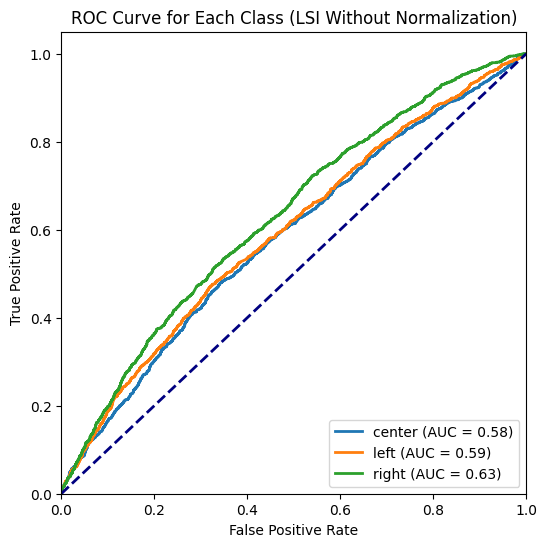

Sample Predictions:


,title,text,topic,position,predicted_position
0,IRS announces 2024 income tax brackets; see wh...,Millions of Americans could take home more pay...,banking and finance,center,left
1,News outlets deny Israeli claim that freelance...,A number of news outlets have strongly rejecte...,facts and fact checking,center,left
2,Senior Ukrainian Military Officer Behind Nord ...,A Ukrainian military officer involved with the...,ukraine war,right,right
3,Nord Stream Pipeline Explosion Was Orchestrate...,A decorated colonel in Ukraine’s special force...,ukraine war,center,right
4,Ukrainian military officer coordinated Nord St...,A senior Ukrainian military officer with deep ...,ukraine war,left,left


In [18]:
# Prepare label encoding and train final model
preprocessor.prepare_tokens()
y_test = preprocessor.le.transform(test_df['position'])

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model, vectorizer = train_dnn_model(train_val_df, embedding_dim, LSIVectorizer, num_classes, device)
x_test = vectorizer.transform(test_df['combined'].tolist())
evaluate_model(test_df, x_test, y_test, model, device, type="LSI Without Normalization")

## Extended cleanup

The second run applies the stronger normalization to training and test text. Its saved report gives 0.40 accuracy and 0.39 macro F1.


TF-IDF matrix shape: (19618, 36462)
LSI components: 768
Model training completed
Classification Report:
              precision    recall  f1-score   support

      center       0.38      0.25      0.30      1566
        left       0.39      0.48      0.43      1671
       right       0.42      0.45      0.43      1668

    accuracy                           0.40      4905
   macro avg       0.39      0.39      0.39      4905
weighted avg       0.40      0.40      0.39      4905



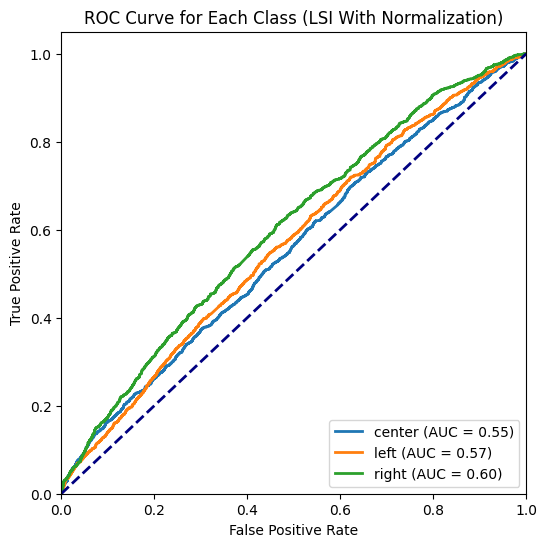

Sample Predictions:


,title,text,topic,position,predicted_position
0,IRS announces 2024 income tax brackets; see wh...,Millions of Americans could take home more pay...,banking and finance,center,right
1,News outlets deny Israeli claim that freelance...,A number of news outlets have strongly rejecte...,facts and fact checking,center,center
2,Senior Ukrainian Military Officer Behind Nord ...,A Ukrainian military officer involved with the...,ukraine war,right,right
3,Nord Stream Pipeline Explosion Was Orchestrate...,A decorated colonel in Ukraine’s special force...,ukraine war,center,right
4,Ukrainian military officer coordinated Nord St...,A senior Ukrainian military officer with deep ...,ukraine war,left,left


In [19]:
# Apply extended normalization
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model, vectorizer = train_dnn_model(norm_train_df, embedding_dim, LSIVectorizer, num_classes, device)
x_test = vectorizer.transform(norm_test_df['combined'].tolist())
evaluate_model(test_df, x_test, y_test, model, device, type="LSI With Normalization")

## Comparison

Basic cleanup performed better in this run. Center recall fell from 0.34 to 0.25 with extended cleaning, while left recall stayed at 0.48. The overall scores remain modest, and the topic field and recurring sources may influence the predictions. The [report](../report/REPORT.md) lists both full classification reports and the main limitations.
